In [1]:
%load_ext autoreload
%autoreload 2

import time
from dataclasses import asdict

import pandas as pd

from fxml.datasets.splits import walk_forward_splits
from fxml.datasets.table import build_table
from fxml.db.connection import connect
from fxml.db.repository import load_bars, load_runs, save_run
from fxml.db.schema import init_db
from fxml.evaluation import plots
from fxml.evaluation.backtest import backtest
from fxml.training.experiment import Settings, run_walk_forward

plots.apply_style()
conn = connect()
init_db(conn)
dev_bars = load_bars(conn, "EURUSD", "H1", start="2001-01-01", end="2015-01-01")
print(len(dev_bars), "bars:", dev_bars.index.min(), "->", dev_bars.index.max())


86847 bars: 2001-01-01 06:00:00+00:00 -> 2014-12-31 17:00:00+00:00


In [2]:
FLAT_COST = 0.8e-4  # 0.8 bps per trade; the 2015+ recorded spread averaged ~0.76 bps
HORIZONS = [4, 12, 24]
dev_runs = {}

for horizon in HORIZONS:
    settings_h = Settings(horizon=horizon)
    table_h = build_table(dev_bars, horizon=horizon)
    folds_h = walk_forward_splits(len(table_h), train_size=31_000, test_size=3_100, gap=horizon)
    print(f"=== horizon {horizon}: {len(table_h)} rows, {len(folds_h)} folds ===")
    start = time.time()
    wf_h = run_walk_forward(table_h, folds_h, settings_h, verbose=False)

    preds = wf_h.predictions
    threshold = (preds["prob_up"] - 0.5).abs().quantile(0.8)
    cost = pd.Series(FLAT_COST, index=preds.index)
    bt = backtest(preds, cost, threshold, horizon)
    bt_slip = backtest(preds, cost, threshold, horizon, extra_cost_bps=0.3)

    m = wf_h.metrics
    summary = {**bt.stats,
               "net_bps_with_0.3_slippage": bt_slip.stats["net_bps_per_trade"],
               "mean_accuracy": m["test_direction_accuracy"].mean(),
               "mean_rank_corr": m["test_rank_corr"].mean(),
               "folds_positive_rank_corr": int((m["test_rank_corr"] > 0).sum()),
               "n_folds": len(folds_h)}
    save_run(conn, f"dev-h{horizon}", "EURUSD", "H1", asdict(settings_h), m,
             summary=summary, notes="development era 2001-2014, flat 0.8 bps cost, top-20% rule")
    dev_runs[horizon] = (wf_h, bt)
    print(f"  done in {(time.time() - start) / 60:.1f} min")


=== horizon 4: 86819 rows, 18 folds ===
  done in 4.1 min
=== horizon 12: 86811 rows, 17 folds ===
  done in 3.2 min
=== horizon 24: 86799 rows, 17 folds ===
  done in 3.2 min


In [3]:
runs = load_runs(conn)
dev = runs[runs["name"].str.startswith("dev-")]
pd.DataFrame(list(dev["summary"]), index=dev["name"])[
    ["n_folds", "mean_accuracy", "mean_rank_corr", "folds_positive_rank_corr",
     "gross_bps_per_trade", "net_bps_per_trade", "net_bps_with_0.3_slippage",
     "sharpe", "max_drawdown"]
]


,n_folds,mean_accuracy,mean_rank_corr,folds_positive_rank_corr,gross_bps_per_trade,net_bps_per_trade,net_bps_with_0.3_slippage,sharpe,max_drawdown
name,,,,,,,,,
dev-h24,17,0.517343,0.004341,9,-0.898231,-1.698231,-1.998231,-0.793366,-0.208955
dev-h12,17,0.512315,0.018575,11,1.958620,1.158620,0.858620,0.833997,-0.112147
dev-h4,18,0.515735,0.028101,14,0.957857,0.157857,-0.142143,0.198431,-0.122561


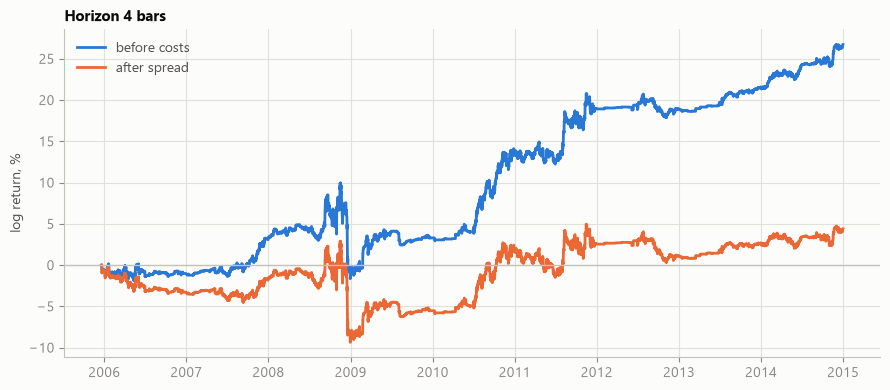

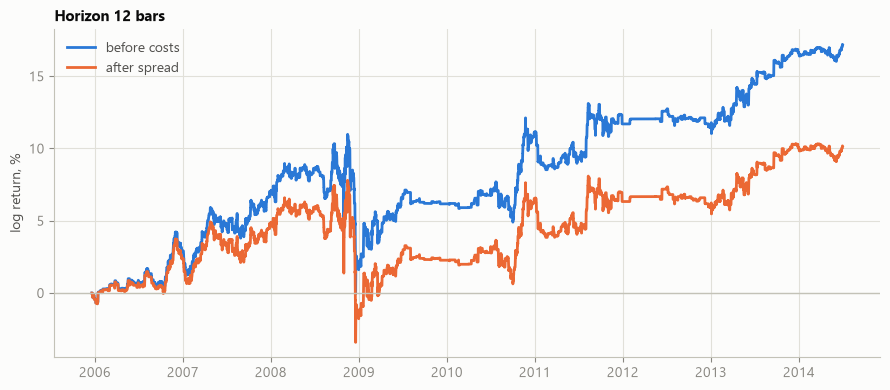

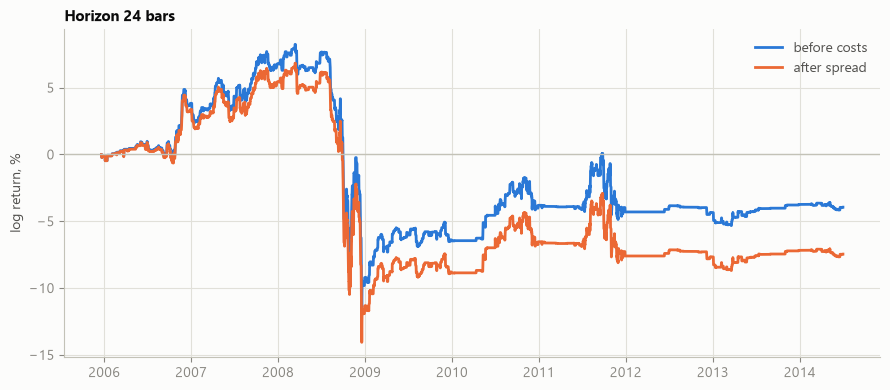

In [4]:
for horizon, (wf_h, bt) in dev_runs.items():
    plots.equity_curve(bt.gross_equity, bt.equity).axes[0].set_title(f"Horizon {horizon} bars")
